<a href="https://colab.research.google.com/github/veorte/registros/blob/main/Actividad8RLineal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 8**
Regresión Lineal

---

*   NOMBRE: Verónica Ortega López, Manuel Olmos Antillón, Brayan Ortega Armendáriz
*   MATRÍCULA: A01841596, A01750748, A01561888

In [49]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


En esta actividad trabajarás con el archivo `diamonds_dataset.csv`, basado en un conjunto de datos sobre características de diamantes, disponible en el paquete ggplot2 de R y en repositorios públicos de análisis de datos.

Los datos fueron recopilados para analizar el precio de los diamantes en función de sus propiedades físicas y cualidades de corte, color y claridad. Los indicadores incluidos son:

* `carat`: Peso del diamante en quilates
* `cut`: Calidad del corte del diamante (Fair, Good, Very Good, Premium, Ideal)
* `color`: Color del diamante, de D (mejor) a J (peor)
* `clarity`: Claridad del diamante (I1, SI2, SI1, VS2, VS1, VVS2, VVS1, IF)
* `depth`: Profundidad total del diamante como porcentaje: z / mean(x, y)
* `table`: Ancho de la tabla del diamante como porcentaje de x
* `x`: Longitud en mm
* `y`: Ancho en mm
* `z`: Profundidad en mm
* `price`: Precio del diamante en dólares estadounidenses. Es la variable de salida o *target*

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [50]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    MinMaxScaler, RobustScaler,
    OrdinalEncoder, OneHotEncoder,
    PolynomialFeatures
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn import set_config
from IPython.display import display

1. Descarga el archivo: `diamonds_dataset.csv` y guarda, en un dataframe (`diamonds_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.
* Verifica si alguna columna contiene valores faltantes.
* Si existen registros duplicados, elimínalos del dataframe y reinicia el índice para que se mantenga consecutivo.

In [51]:
diamonds_df = pd.read_csv("/content/drive/MyDrive/2. MNA Tec/Ciencia Analitica TC5053.10/Materiales para Tareas/Actividad8RegresionLineal/diamonds_dataset.csv")

diamonds_df.head()

,carat,cut,color,clarity,depth,table,x,y,z,price
0,0.23,Ideal,E,SI2,61.5,55.0,3.95,3.98,2.43,326
1,0.21,Premium,E,SI1,59.8,61.0,3.89,3.84,2.31,326
2,0.23,Good,E,VS1,56.9,65.0,4.05,4.07,2.31,327
3,0.29,Premium,I,VS2,62.4,58.0,4.20,4.23,2.63,334
4,0.31,Good,J,SI2,63.3,58.0,4.34,4.35,2.75,335


In [52]:
diamonds_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53916 entries, 0 to 53915
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53916 non-null  float64
 1   cut      53916 non-null  object 
 2   color    53916 non-null  object 
 3   clarity  53916 non-null  object 
 4   depth    53916 non-null  float64
 5   table    53916 non-null  float64
 6   x        53916 non-null  float64
 7   y        53916 non-null  float64
 8   z        53916 non-null  float64
 9   price    53916 non-null  int64  
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB


Encontramos 7 columnas númericas (6 con números decimales y 1 con números enteros) y 3 columnas categoricas.

In [53]:
# Contar valores únicos

diamonds_df.nunique()

,0
carat,271
cut,5
color,7
clarity,8
depth,184
table,127
x,550
y,549
z,371
price,11595


In [54]:
# Identificar valores faltantes

diamonds_df.isnull().sum()

,0
carat,0
cut,0
color,0
clarity,0
depth,0
table,0
x,0
y,0
z,0
price,0


In [55]:
# Eliminar duplicados y re iniciar el indice

duplicados = diamonds_df.duplicated().sum()

diamonds_df = (
    diamonds_df
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Duplicados encontrados:", duplicados)
print("Dimensiones finales:", diamonds_df.shape)

Duplicados encontrados: 145
Dimensiones finales: (53771, 10)




*   El conjunto de datos contiene inicialmente 53,916 registros y 10 variables.
* De estas 10 variables tenemos 7 númericas y 3 categoricas
* No se identificaron valores faltantes
* Tenemos 145 registros duplicados mismos que se eliminaron
* Una vez re iniciado el indice tenemos 53,771 registros


2. Obtén las estadísticas descriptivas, separando las variables numéricas y las categóricas. De estas últimas incluye las tablas de frecuencia.
* Para las variables numéricas genera histogramas y boxplots para explorar la distribución y la dispersión.
* Para las variables categóricas utiliza diagramas de barras para visualizar la frecuencia de cada categoría.

In [56]:
# Separamos las variables en númericas y categoricas creando 2 listas para aplicar operaciones distintas a variables númericas y de texto

numeric_cols = diamonds_df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = diamonds_df.select_dtypes(
    include=["object"]
).columns.tolist()

In [57]:
diamonds_df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
carat,53771.0,0.797323,0.472474,0.20,0.40,0.70,1.04,4.50
depth,53771.0,61.748160,1.429519,43.00,61.00,61.80,62.50,79.00
table,53771.0,57.457635,2.233192,43.00,56.00,57.00,59.00,95.00
x,53771.0,5.731280,1.118102,3.73,4.71,5.70,6.54,10.23
y,53771.0,5.734618,1.138982,3.68,4.72,5.71,6.54,58.90
z,53771.0,3.539774,0.701677,1.07,2.91,3.53,4.03,31.80
price,53771.0,3930.320545,3984.687429,326.00,951.00,2401.00,5323.50,18823.00


In [58]:
display(diamonds_df[categorical_cols].describe())

for col in categorical_cols:
    frecuencia = diamonds_df[col].value_counts()
    porcentaje = diamonds_df[col].value_counts(
        normalize=True
    ) * 100

    tabla = pd.DataFrame({
        "Frecuencia": frecuencia,
        "Porcentaje": porcentaje.round(2)
    })

    display(tabla)

,cut,color,clarity
count,53771,53771,53771
unique,5,7,8
top,Ideal,G,SI1
freq,21485,11254,13030


,Frecuencia,Porcentaje
cut,,
Ideal,21485,39.96
Premium,13737,25.55
Very Good,12065,22.44
Good,4888,9.09
Fair,1596,2.97


,Frecuencia,Porcentaje
color,,
G,11254,20.93
E,9776,18.18
F,9517,17.70
H,8266,15.37
D,6753,12.56
I,5404,10.05
J,2801,5.21


,Frecuencia,Porcentaje
clarity,,
SI1,13030,24.23
VS2,12225,22.74
SI2,9140,17.00
VS1,8155,15.17
VVS2,5056,9.40
VVS1,3646,6.78
IF,1784,3.32
I1,735,1.37


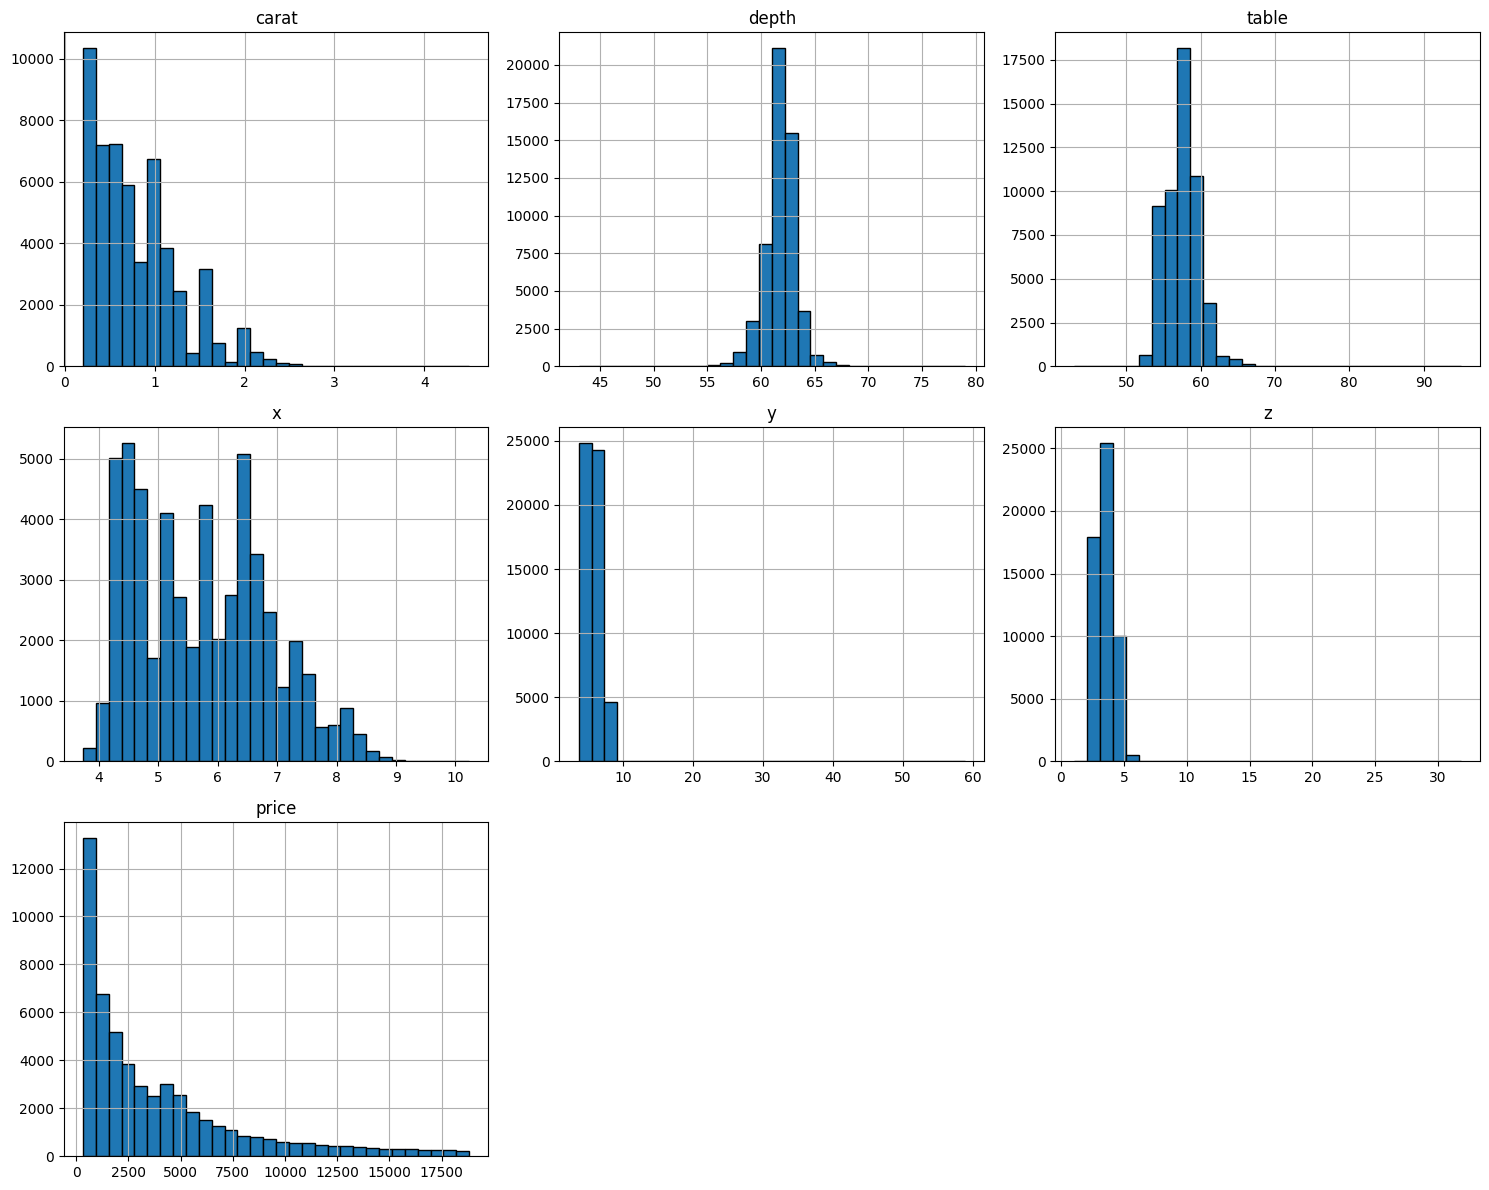

In [59]:
diamonds_df[numeric_cols].hist(
    bins=30,
    figsize=(15, 12),
    edgecolor="black"
)

plt.tight_layout()
plt.show()

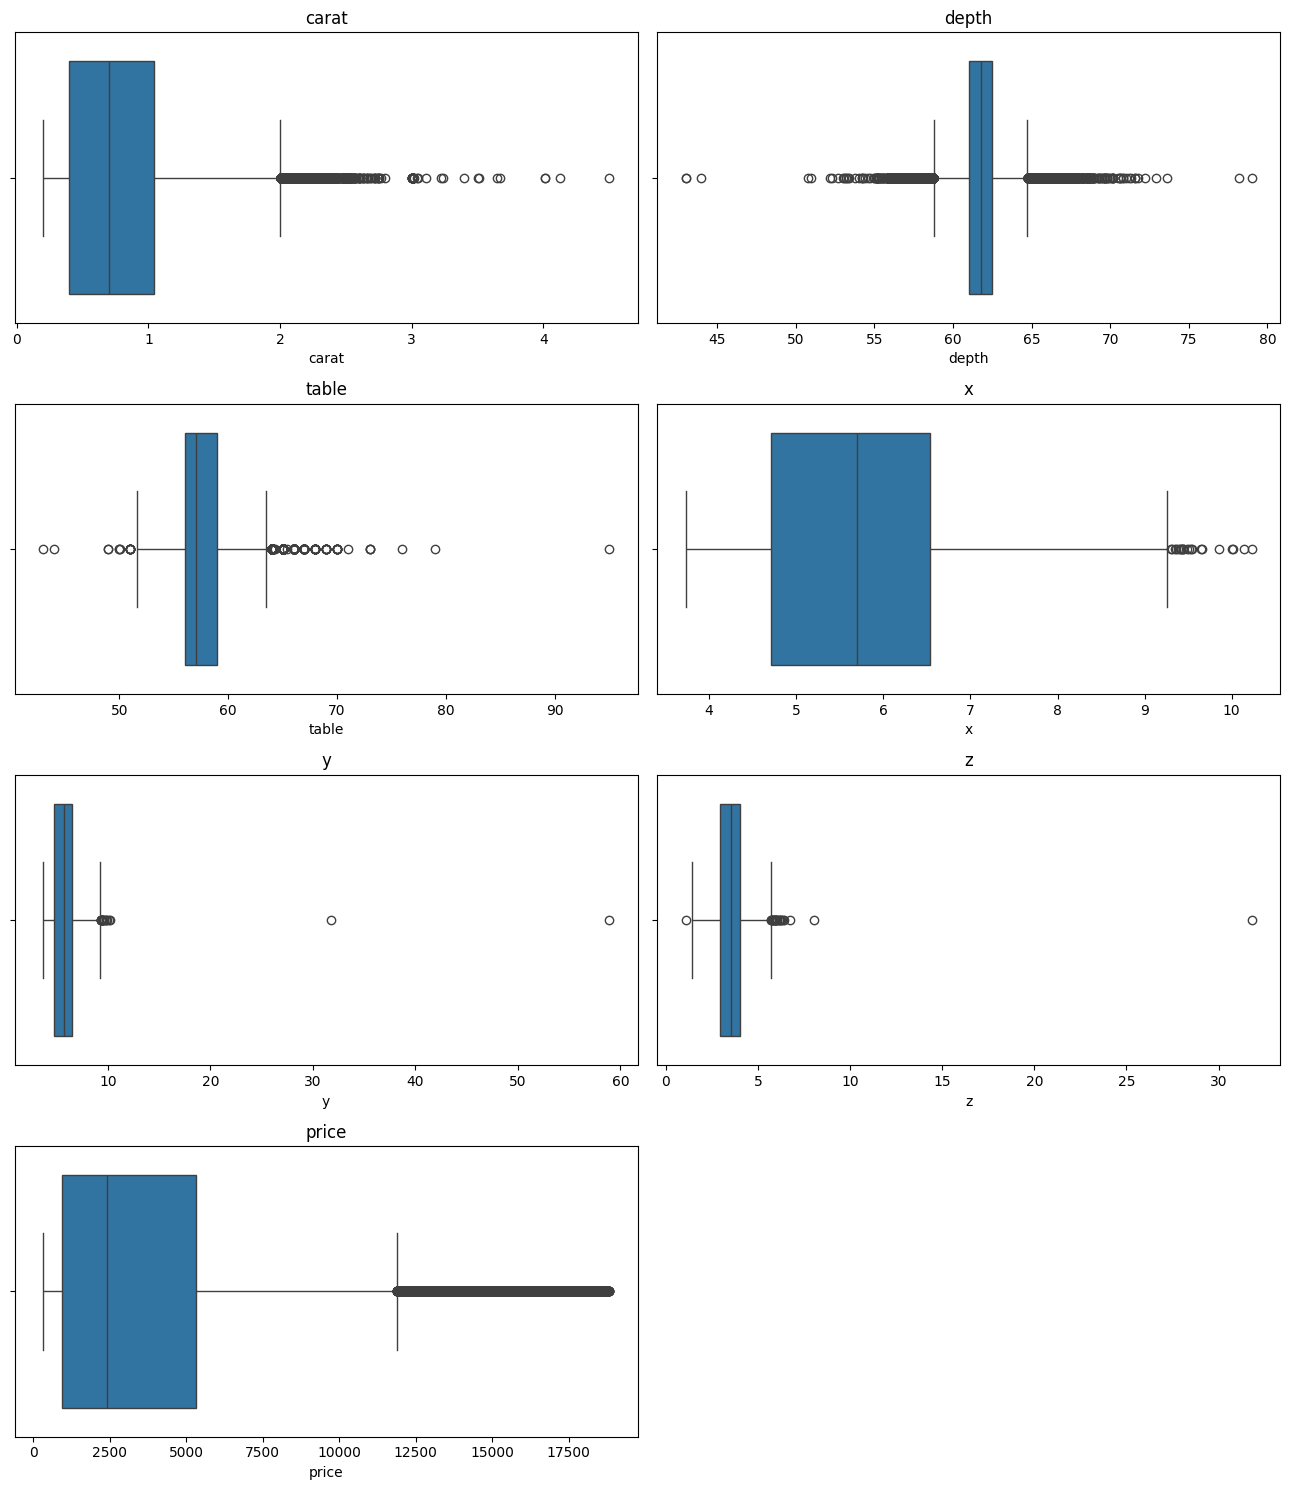

In [60]:
fig, axes = plt.subplots(
    4, 2, figsize=(13, 15)
)

for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(
        x=diamonds_df[col],
        ax=ax
    )
    ax.set_title(col)

for ax in axes.flat[len(numeric_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

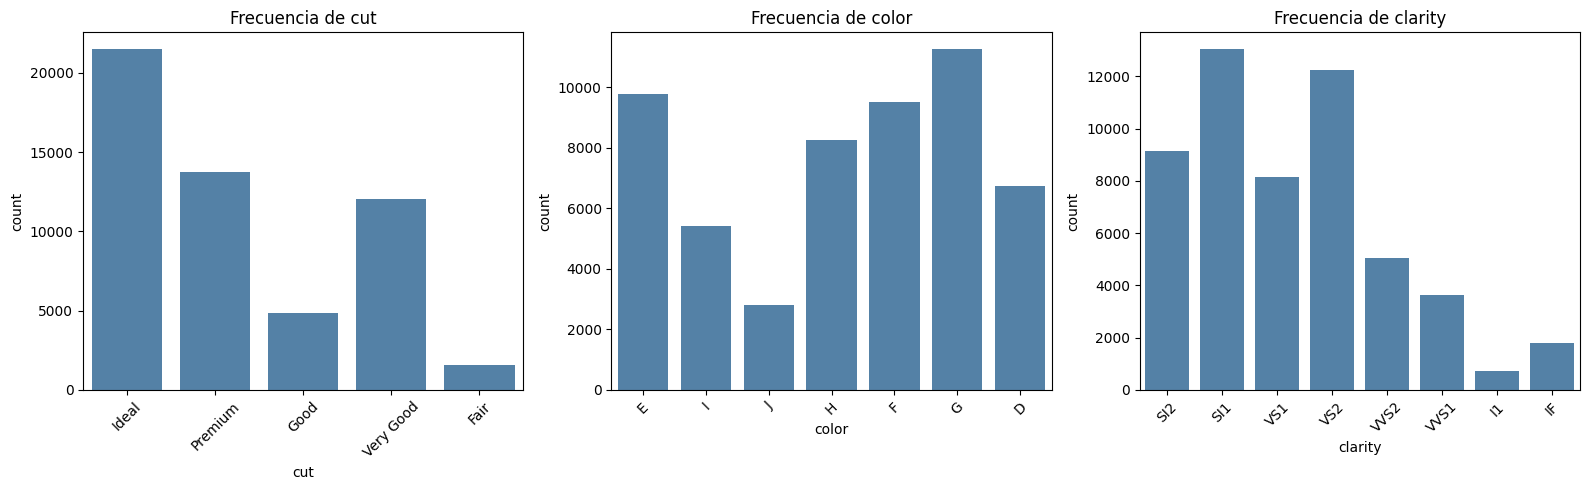

In [61]:
fig, axes = plt.subplots(
    1, 3, figsize=(16, 5)
)

for ax, col in zip(axes, categorical_cols):
    sns.countplot(
        data=diamonds_df,
        x=col,
        ax=ax,
        color="steelblue"
    )
    ax.set_title(f"Frecuencia de {col}")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

3. Explora relaciones bivariadas en el conjunto de datos mediante gráficos:
* Boxplots que muestren la distribución del precio para cada categoría de color, asegurándose de que las categorías se muestren en el orden de calidad de diamante de mejor a peor: D, E, F, G, H, I, J.
* ¿La tendencia de los precios se comporta como esperabas? Identifica si alguna otra variable podría estar influyendo en la tendencia observada por color y comenta tus observaciones.
* Gráfico de dispersión del precio frente al peso de los diamantes, coloreando los puntos según la categoría de calidad del corte.
* ¿Qué relación se observa entre el peso del diamante y su precio según la calidad del corte?

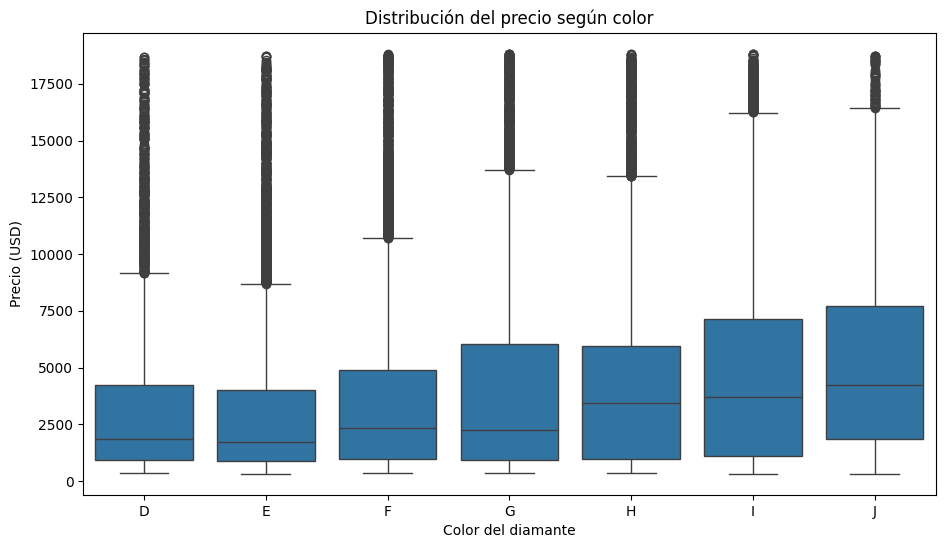

In [62]:
color_order = ["D", "E", "F", "G", "H", "I", "J"]

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=diamonds_df,
    x="color",
    y="price",
    order=color_order
)

plt.title("Distribución del precio según color")
plt.xlabel("Color del diamante")
plt.ylabel("Precio (USD)")
plt.show()

Al parecer la distribución de precios no sigue la tendencia en la cual a mejor color, los diamantes pueden ser más costosos.
Puede deberse a que el precio de un diamante no esta determinado unicamente por el color, tambien influyen en su precio el peso, claridad y corte.

In [63]:
diamonds_df.groupby("color")[
    ["price", "carat"]
].median().reindex(color_order)

,price,carat
color,,
D,1842.0,0.53
E,1741.5,0.53
F,2345.0,0.70
G,2242.0,0.70
H,3447.0,0.90
I,3719.0,1.00
J,4234.0,1.11


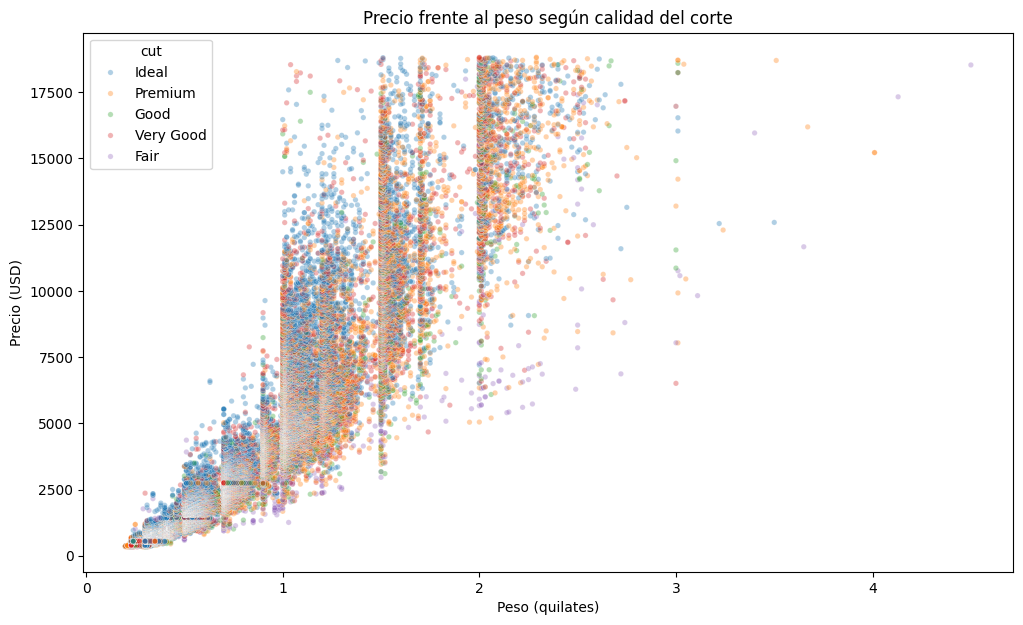

In [64]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=diamonds_df,
    x="carat",
    y="price",
    hue="cut",
    alpha=0.35,
    s=15
)

plt.title("Precio frente al peso según calidad del corte")
plt.xlabel("Peso (quilates)")
plt.ylabel("Precio (USD)")
plt.show()

El peso del diamante muestra una asociación positiva con su precio, sin embargo la dispersión de los puntos puede indicar que el peso no es la única variable que explica completamente las diferencias en el precio. El resto de las caracterisitcas (color, corte o claridad) podrían contribuir a explicar la variabilidad observada.

4. Dibuja un mapa de calor con la matriz de correlación para las variables numéricas del conjunto de datos.
* Identifica los pares de variables cuya correlación sea superior a 0.9 e imprímelos.
* Analiza la correlación entre los predictores (excluyendo `price`), identifica si un único predictor captura información que también está presente en varios otros y elimina los predictores redundantes para simplificar la complejidad de los modelos que construirás más adelante.
* Vuelve a generar el mapa de calor para verificar que ya no queden predictores altamente correlacionados.

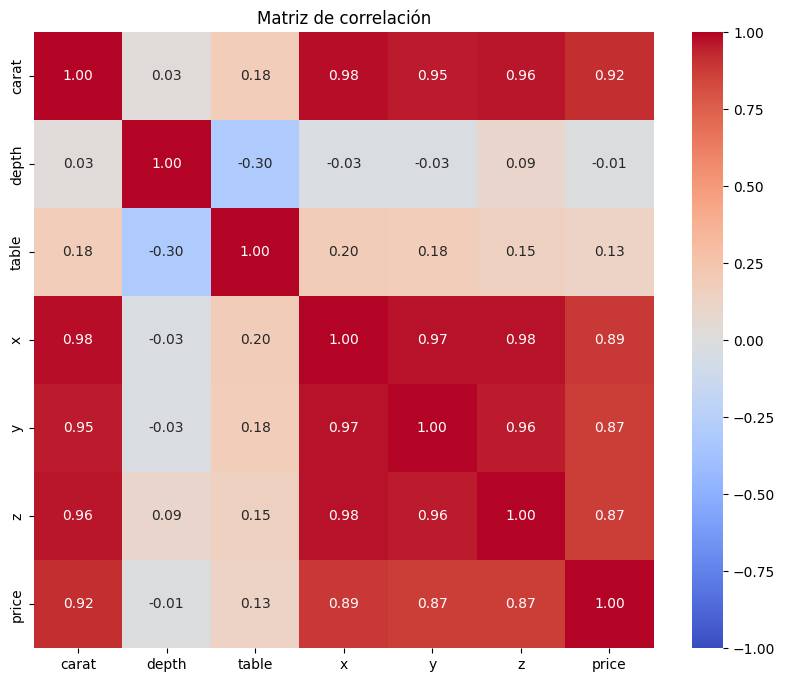

In [65]:
# Primero calcular la matriz de correlación

corr_matrix = diamonds_df[numeric_cols].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Matriz de correlación")
plt.show()

In [66]:
# Eliminar predictores redundantes

columns_to_drop = ["x", "y", "z"]

diamonds_model_df = diamonds_df.drop(
    columns=columns_to_drop
)

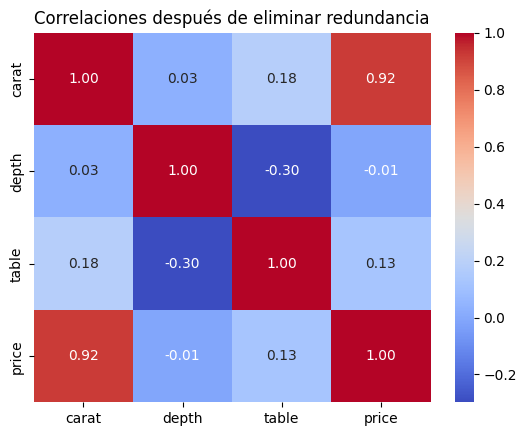

In [67]:
# Revisar la nueva correlación

new_corr = diamonds_model_df.select_dtypes(
    include="number"
).corr()

sns.heatmap(
    new_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlaciones después de eliminar redundancia")
plt.show()

In [68]:
predictor_corr = new_corr.drop(
    index="price",
    columns="price"
).abs()

upper_predictors = predictor_corr.where(
    np.triu(
        np.ones(predictor_corr.shape),
        k=1
    ).astype(bool)
)

display(upper_predictors.stack()[
    lambda s: s > 0.9
])

,,0


5. Construye un modelo de regresión simple utilizando únicamente la variable predictora que tenga la mayor correlación con `price`. Para ello:
* Asigna esta variable a `X` y `price` a `y` y divide el conjunto de datos en entrenamiento y prueba (80:20), usando `random_state=1` para garantizar reproducibilidad.
* Entrena un modelo con `LinearRegression()` de scikit-learn y evalúalo en el conjunto de prueba utilizando las métricas `RMSE` (Root Mean Squared Error) y `R²` (coeficiente de determinación).
* Añade los valores obtenidos a un dataframe de resultados, que incluya el nombre del modelo (*Baseline*) y una columna para cada métrica.
* Muestra la ecuación de la regresión lineal utilizando el intercepto y el coeficiente asociado al predictor. La ecuación debe tener la forma:
> `price = intercepto + coeficiente × predictor`

In [69]:
# Debido a la correlación positiva encontrada entre carat y price (0.922) usaremos carat para el primer modelo

X = diamonds_model_df[["carat"]]
y = diamonds_model_df["price"]

In [70]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=1
)

In [71]:
baseline = LinearRegression()

baseline.fit(X_train, y_train)

y_pred_baseline = baseline.predict(X_test)

In [72]:
# Evaluar el modelo

rmse_baseline = np.sqrt(
    mean_squared_error(y_test, y_pred_baseline)
)

r2_baseline = r2_score(
    y_test, y_pred_baseline
)

results_df = pd.DataFrame([{
    "Modelo": "Baseline",
    "RMSE": rmse_baseline,
    "R2": r2_baseline
}])

display(results_df)

,Modelo,RMSE,R2
0,Baseline,1532.43849,0.84618


In [73]:
intercepto = baseline.intercept_
coeficiente = baseline.coef_[0]

print(
    f"price = {intercepto:.2f} "
    f"+ ({coeficiente:.2f} × carat)"
)

price = -2276.79 + (7792.73 × carat)


6. Utiliza todas las variables como predictoras para crear un segundo modelo:
* Haz la asignación correspondiente en `X` y `y` y divide en entrenamiento y prueba usando la misma configuración del ejercicio anterior.
* Prepara un transformador, denominado `preprocessing`, para aplicar escalamiento robusto a los predictores numéricos y codificación ordinal a los categóricos. Asegúrate de respetar el orden correcto de cada categoría, tal como se indica en la descripción de las variables.
* Construye un pipeline que combine el transformador creado con un modelo de regresión lineal.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *Ordinal_Robust*.

In [74]:
# Asignación correspondiente en x y y

X = diamonds_model_df.drop(columns="price")
y = diamonds_model_df["price"]

numeric_features = X.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X.select_dtypes(
    include="object"
).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=1
)

In [75]:
# Definición del orden de las categorias de menor a mayor calidad

cut_order = [
    "Fair", "Good", "Very Good",
    "Premium", "Ideal"
]

color_order_ordinal = [
    "J", "I", "H", "G", "F", "E", "D"
]

clarity_order = [
    "I1", "SI2", "SI1", "VS2",
    "VS1", "VVS2", "VVS1", "IF"
]



In [76]:
preprocessing = ColumnTransformer(
    transformers=[
        (
            "numeric",
            RobustScaler(),
            numeric_features
        ),
        (
            "categorical",
            OrdinalEncoder(
                categories=[
                    cut_order,
                    color_order_ordinal,
                    clarity_order
                ]
            ),
            categorical_features
        )
    ]
)

In [77]:
# Construcción del pipeline

ordinal_robust = Pipeline(
    steps=[
        ("preprocessing", preprocessing),
        ("regression", LinearRegression())
    ]
)

ordinal_robust.fit(X_train, y_train)

y_pred_ordinal = ordinal_robust.predict(X_test)

In [78]:
rmse_ordinal = np.sqrt(
    mean_squared_error(y_test, y_pred_ordinal)
)

r2_ordinal = r2_score(
    y_test, y_pred_ordinal
)

results_df.loc[len(results_df)] = [
    "Ordinal_Robust",
    rmse_ordinal,
    r2_ordinal
]

display(results_df)

,Modelo,RMSE,R2
0,Baseline,1532.438490,0.846180
1,Ordinal_Robust,1216.822219,0.903016


En la comparación del primer modelo Baseline al segundo vemos que el RMSE disminuye y el R2 aumenta por lo que podemos suponer que el nuevo modelo ofrece un mejor ajuste sobre el conjunto de prueba.

7. Prepara otro transformador, llamado `preprocessing2`, que aplique escalamiento Min-Max a los predictores numéricos y codificación one-hot a los categóricos, asegurando `drop='first'` para prevenir multicolinealidad en las variables dummies generadas.
* Construye otro pipeline utilizando este nuevo transformador y, a continuación, entrena y evalúa el modelo.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *OHE_MinMax*.

In [79]:
preprocessing2 = ColumnTransformer(
    transformers=[
        (
            "numeric",
            MinMaxScaler(),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                categories=[
                    cut_order,
                    color_order_ordinal,
                    clarity_order
                ],
                drop="first",
                handle_unknown="error",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

In [80]:
ohe_minmax = Pipeline(
    steps=[
        ("preprocessing", preprocessing2),
        ("regression", LinearRegression())
    ]
)

ohe_minmax.fit(X_train, y_train)

y_pred_ohe = ohe_minmax.predict(X_test)

In [81]:
rmse_ohe = np.sqrt(
    mean_squared_error(y_test, y_pred_ohe)
)

r2_ohe = r2_score(
    y_test, y_pred_ohe
)

results_df.loc[len(results_df)] = [
    "OHE_MinMax",
    rmse_ohe,
    r2_ohe
]

display(results_df)

,Modelo,RMSE,R2
0,Baseline,1532.438490,0.846180
1,Ordinal_Robust,1216.822219,0.903016
2,OHE_MinMax,1142.519131,0.914499


Nuevamente en la comparación de los modelos, contamos con una disminución en el RMSE y un incremento en el R2, por lo cual el tercer modelo ofrece un mejor ajuste.

8. Modifica el pipeline anterior para emplear regresión polinomial de segundo grado y evalúa si esto mejora el ajuste del modelo.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *PolynomialDegree2*.

In [82]:
polynomial_model = Pipeline(
    steps=[
        ("preprocessing", preprocessing2),
        (
            "polynomial",
            PolynomialFeatures(
                degree=2,
                include_bias=False
            )
        ),
        ("regression", LinearRegression())
    ]
)

polynomial_model.fit(X_train, y_train)

y_pred_poly = polynomial_model.predict(X_test)

In [83]:
rmse_poly = np.sqrt(
    mean_squared_error(y_test, y_pred_poly)
)

r2_poly = r2_score(
    y_test, y_pred_poly
)

results_df.loc[len(results_df)] = [
    "PolynomialDegree2",
    rmse_poly,
    r2_poly
]

display(results_df)

,Modelo,RMSE,R2
0,Baseline,1532.438490,0.846180
1,Ordinal_Robust,1216.822219,0.903016
2,OHE_MinMax,1142.519131,0.914499
3,PolynomialDegree2,748.838380,0.963270


9. Ordena el dataframe de resultados según el `R²`, de manera que el modelo con mejor desempeño aparezca primero.
* Para dicho modelo, crea un gráfico de dispersión de los valores reales frente a los predichos, e incluye una línea diagonal de referencia para indicar una predicción perfecta.

In [84]:
results_df = results_df.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Modelo,RMSE,R2
0,PolynomialDegree2,748.8384,0.9633
1,OHE_MinMax,1142.5191,0.9145
2,Ordinal_Robust,1216.8222,0.9030
3,Baseline,1532.4385,0.8462


In [85]:
# Seleccionar el mejor modelo

models = {
    "Baseline": baseline,
    "Ordinal_Robust": ordinal_robust,
    "OHE_MinMax": ohe_minmax,
    "PolynomialDegree2": polynomial_model
}

best_model_name = results_df.iloc[0]["Modelo"]
best_model = models[best_model_name]

if best_model_name == "Baseline":
    best_predictions = y_pred_baseline
else:
    best_predictions = best_model.predict(X_test)

print("Mejor modelo:", best_model_name)

Mejor modelo: PolynomialDegree2


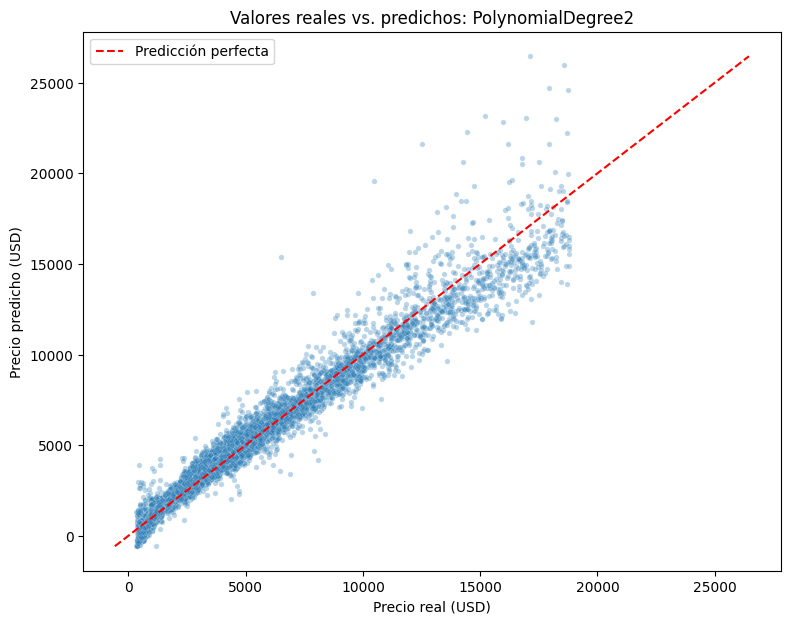

In [86]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    x=y_test,
    y=best_predictions,
    alpha=0.3,
    s=15
)

min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--",
    label="Predicción perfecta"
)

plt.xlabel("Precio real (USD)")
plt.ylabel("Precio predicho (USD)")
plt.title(f"Valores reales vs. predichos: {best_model_name}")
plt.legend()
plt.show()

10. Muestra la representación gráfica del pipeline para ubicar la posición de cada elemento dentro del flujo del modelo.
* Obtén los nombres de todas las columnas después del preprocesamiento (numéricas y dummies de categóricas).
* Extrae los nombres de las columnas polinómicas.
* Recupera los coeficientes y el intercepto del modelo de regresión lineal.
* Ordena los coeficientes por su valor absoluto para mostrar los 10 más importantes y da conclusiones sobre cómo los distintos factores influyen en el precio.

In [87]:
set_config(display="diagram")

display(polynomial_model)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric', MinMaxScaler(),
                                                  ['carat', 'depth', 'table']),
                                                 ('categorical',
                                                  OneHotEncoder(categories=[['Fair',
                                                                             'Good',
                                                                             'Very '
                                                                             'Good',
                                                                             'Premium',
                                                                             'Ideal'],
                                                                            ['J',
                                                                             'I',
                                                                             'H',
                                                                             'G',
                                                                             'F',
                                                                             'E',
                                                                             'D'],
                                                                            ['I1',
                                                                             'SI2',
                                                                             'SI1',
                                                                             'VS2',
                                                                             'VS1',
                                                                             'VVS2',
                                                                             'VVS1',
                                                                             'IF']],
                                                                drop='first',
                                                                sparse_output=False),
                                                  ['cut', 'color',
                                                   'clarity'])])),
                ('polynomial', PolynomialFeatures(include_bias=False)),
                ('regression', LinearRegression())])

In [88]:
preprocessor_fitted = polynomial_model.named_steps[
    "preprocessing"
]

feature_names = (
    preprocessor_fitted.get_feature_names_out()
)

display(pd.DataFrame({
    "Variable transformada": feature_names
}))

,Variable transformada
0,numeric__carat
1,numeric__depth
2,numeric__table
3,categorical__cut_Good
4,categorical__cut_Very Good
5,categorical__cut_Premium
6,categorical__cut_Ideal
7,categorical__color_I
8,categorical__color_H
9,categorical__color_G


In [89]:
poly_fitted = polynomial_model.named_steps[
    "polynomial"
]

polynomial_names = poly_fitted.get_feature_names_out(
    feature_names
)

print(
    "Total de variables polinomiales:",
    len(polynomial_names)
)

display(pd.DataFrame({
    "Variable polinomial": polynomial_names
}))

Total de variables polinomiales: 230


,Variable polinomial
0,numeric__carat
1,numeric__depth
2,numeric__table
3,categorical__cut_Good
4,categorical__cut_Very Good
...,...
225,categorical__clarity_VVS2 categorical__clarity...
226,categorical__clarity_VVS2 categorical__clarity_IF
227,categorical__clarity_VVS1^2
228,categorical__clarity_VVS1 categorical__clarity_IF


In [90]:
regression_fitted = polynomial_model.named_steps[
    "regression"
]

coeficientes = regression_fitted.coef_
intercepto = regression_fitted.intercept_

coef_df = pd.DataFrame({
    "Variable": polynomial_names,
    "Coeficiente": coeficientes
})

coef_df["Valor absoluto"] = (
    coef_df["Coeficiente"].abs()
)

coef_df = coef_df.sort_values(
    by="Valor absoluto",
    ascending=False
)

display(coef_df.head(10))

print("Intercepto:", intercepto)

,Variable,Coeficiente,Valor absoluto
20,numeric__carat^2,55138.497649,55138.497649
39,numeric__carat categorical__clarity_IF,49898.316662,49898.316662
38,numeric__carat categorical__clarity_VVS1,46662.337832,46662.337832
37,numeric__carat categorical__clarity_VVS2,44769.175537,44769.175537
36,numeric__carat categorical__clarity_VS1,40020.571581,40020.571581
35,numeric__carat categorical__clarity_VS2,37083.049534,37083.049534
34,numeric__carat categorical__clarity_SI1,31988.729725,31988.729725
0,numeric__carat,-26433.862957,26433.862957
33,numeric__carat categorical__clarity_SI2,24361.063098,24361.063098
32,numeric__carat categorical__color_D,20652.315075,20652.315075


Intercepto: 2839.7350124844293


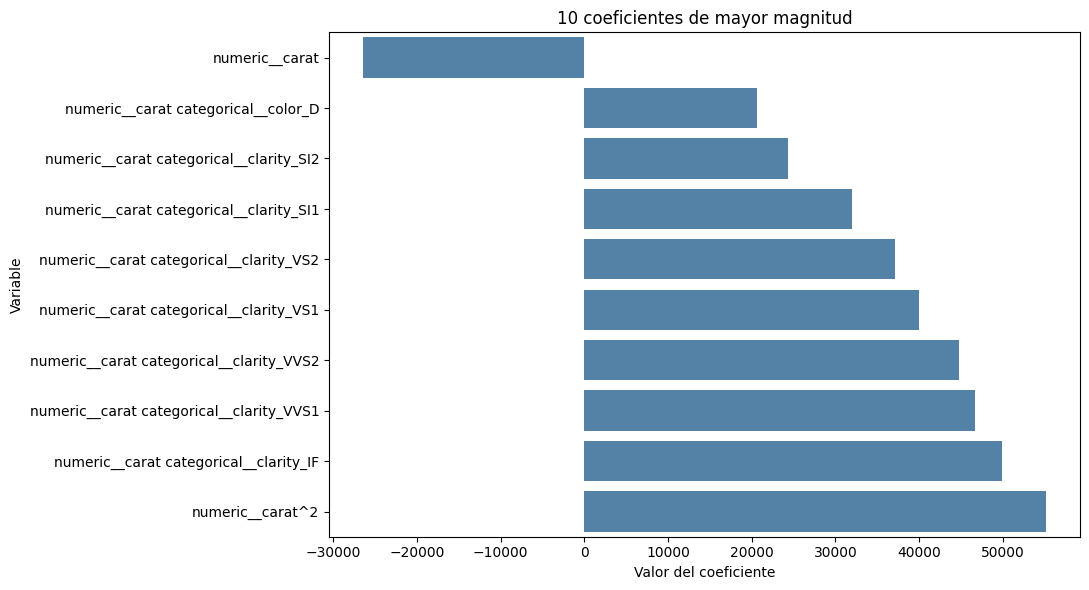

In [91]:
top10 = coef_df.head(10).sort_values(
    by="Coeficiente"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top10,
    x="Coeficiente",
    y="Variable",
    color="steelblue"
)

plt.title("10 coeficientes de mayor magnitud")
plt.xlabel("Valor del coeficiente")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

El desarrollo de esta práctica nos permitió aplicar diferentes técnicas de aprendizaje supervisado para predecir el precio de los diamantes a partir de sus características físicas y de calidad.

Se construyeron cuatro modelos de regresión:
* Baseline
* Ordinal_Robust
* OHE_MinMax
* PolynomialDegree2


El modelo PolynomialDegree2	obtuvo el mejor desempeño, con un coeficiente de determinación (R²) de 0.9633 y un error cuadrático medio raíz (RMSE) de 1532.438490. En comparación con el modelo Baseline, presentó una reducción del RMSE de 48%, lo que indica una mejora en la precisión de las predicciones.

La incorporación de variables categóricas, como el corte, color y claridad, permitió evaluar información adicional al peso del diamante, que por sí solo presenta una fuerte correlación con el precio. Asimismo, la comparación entre codificación ordinal y one-hot permitió analizar cómo la representación de estas características influye en el desempeño de los modelos.

Por otra parte, la regresión polinomial de segundo grado permitió incorporar relaciones no lineales e interacciones entre variables, ofreciendo una representación más flexible del comportamiento del precio. Su efectividad debe valorarse a partir de las métricas obtenidas sobre los datos de prueba, considerando que una mayor complejidad no garantiza necesariamente mejores predicciones.

Finalmente, se identificaron algunas limitaciones, como la presencia de valores atípicos, la correlación entre características físicas y el riesgo de sobreajuste en modelos más complejos.

---

**Declaración de uso de IA**

OpenAI. (2026). ChatGPT (basado en GPT-6), utilizado para depuración de código y explicación del significado y consideraciones de la variables usadas en el ejercicio.. https://chat.openai.com/

Gemini. (2026). Gemini 3.5 Flash [Modelo de lenguaje], usado para la revisión y corrección de errores de syntaxis en código. https://gemini.google.com/

---